# ACTIVIDAD AUTÓNOMA Y EXPERIMENTAL

![Mi imagen](images.png)

**Analizar un conjunto de datos de 101.766 hospitalizaciones de pacientes con diabetes, aplicar técnicas de normalización y estandarización y comparar los resultados..**

**Fórmula:**


**Nombre:** Vinicio Sarabia 

**Fecha:** 09-11-2026

**Link:** <a href="https://github.com/viniciosarabia68-arch/Practicas-Maching-Learning" target="_blank">Mi repositorio de GitHub</a>

In [33]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.



# Fase 1: Comprensión del negocio (CRISP-DM)

## Descripción del problema

Las readmisiones hospitalarias de pacientes con diabetes representan un tema importante para los hospitales, porque permiten estudiar la frecuencia con la que los pacientes regresan después de recibir atención médica.

Esta práctica busca explorar los datos de hospitalizaciones para comprender sus características y preparar las variables antes de aplicar técnicas de Machine Learning.

## Actores interesados

- **Hospitales:** para conocer las características de las hospitalizaciones.
- **Personal médico:** para comprender mejor los registros de atención.
- **Analistas de datos:** para revisar la calidad y distribución de la información.
- **Administradores hospitalarios:** para apoyar la planificación de recursos.

## Objetivo general

Analizar las características de 101.766 hospitalizaciones de pacientes con diabetes mediante la metodología CRISP-DM, preparando siete variables cuantitativas con técnicas de normalización y estandarización.

## Preguntas de análisis

1. ¿Cómo se distribuyen las hospitalizaciones según la duración y la cantidad de medicamentos administrados?
2. ¿Cuál es la frecuencia de las categorías de readmisión hospitalaria?
3. ¿Cómo cambian las escalas de las variables después de aplicar Min-Max y Z-score?

## Criterios de éxito

- Analizar los 101.766 registros originales.
- Identificar los datos faltantes y posibles duplicados.
- Crear gráficos y estadísticas descriptivas.
- Normalizar siete variables con MinMaxScaler.
- Estandarizar siete variables con StandardScaler.
- Exportar los resultados a archivos CSV.

## Variable de referencia: readmitted

Esta variable indica si el paciente fue readmitido después de una hospitalización.

- **NO:** no se registró una readmisión.
- **<30:** readmisión en menos de 30 días.
- **>30:** readmisión después de 30 días.

Esta variable es categórica y no será normalizada ni estandarizada.

## Limitaciones y confidencialidad

Los datos corresponden a hospitalizaciones registradas entre 1999 y 2008 en hospitales de Estados Unidos, por lo que no necesariamente representan la situación hospitalaria actual.

Un mismo paciente puede aparecer en varios registros debido a diferentes hospitalizaciones. Por esta razón, el número de registros no equivale al número de pacientes únicos.

La información se utilizará únicamente con fines académicos, respetando la confidencialidad de los pacientes y sin intentar identificarlos. Los resultados serán descriptivos y no permitirán establecer diagnósticos ni relaciones causales.


In [34]:
from ucimlrepo import fetch_ucirepo
dataset = fetch_ucirepo(id=296)
df = dataset.data.original.copy()
print("Filas y columnas:", df.shape)

assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."

display(df.head())
display(dataset.variables)
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)


C:\Users\ACER\anaconda3\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Filas y columnas: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


In [35]:
from datetime import datetime
from importlib.metadata import version
import pandas as pd

print("Fecha de descarga:", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Dimensiones:", df.shape)
print("Registros:", len(df))
print("Columnas:", len(df.columns))
print("Versión de pandas:", pd.__version__)
print("Versión de ucimlrepo:", version("ucimlrepo"))

Fecha de descarga: 2026-11-09 11:58:05
Dimensiones: (101766, 50)
Registros: 101766
Columnas: 50
Versión de pandas: 3.0.3
Versión de ucimlrepo: 0.0.7



# Fase 2: Comprensión de los datos (CRISP-DM)

## Análisis inicial del dataset

En esta fase se analiza la estructura del conjunto de datos médicos para identificar la cantidad de registros, columnas, tipos de datos y pacientes únicos.

El objetivo es comprender la información disponible, detectar posibles problemas de calidad y preparar los datos para su posterior normalización y estandarización.


In [36]:
print("Dimensiones:", df.shape)
print("Total de hospitalizaciones:", len(df))
print("Pacientes únicos:", df["patient_nbr"].nunique())
print("Encuentros únicos:", df["encounter_id"].nunique())
print("\nInformación general del dataset:")
df.info()

Dimensiones: (101766, 50)
Total de hospitalizaciones: 101766
Pacientes únicos: 71518
Encuentros únicos: 101766

Información general del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  


## Interpretación del análisis inicial

El conjunto de datos contiene 101.766 registros y 50 columnas, que representan hospitalizaciones de pacientes con diabetes.

La variable `patient_nbr` permite identificar cuántos pacientes diferentes aparecen en el conjunto de datos, mientras que `encounter_id` identifica cada encuentro hospitalario.

Es importante diferenciar las hospitalizaciones de los pacientes únicos, ya que una misma persona puede haber sido hospitalizada varias veces.

La función `df.info()` permite conocer los nombres de las columnas, los tipos de datos y la cantidad de valores no nulos.



## Diccionario de variables

El conjunto de datos contiene 50 variables relacionadas con las hospitalizaciones de pacientes con diabetes.

Se identifican variables cuantitativas, categóricas e identificadores. Esta clasificación permite determinar cuáles pueden utilizarse para la normalización y estandarización.

El diccionario incluye el nombre, significado, tipo de dato observado, tipo conceptual, unidades o categorías y rol analítico de cada columna.


In [37]:
import pandas as pd
metadata = dataset.variables.set_index("name")
identificadores = ["encounter_id", "patient_nbr"]
cuantitativas = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

otras_cuantitativas = ["number_diagnoses"]
medicamentos = list(df.columns[24:47])
diccionario = []

for columna in df.columns:

    if columna in identificadores:
        tipo = "Identificador"
        unidad = "Código"
        rol = "Identificación, no escalar"

    elif columna in cuantitativas:
        tipo = "Cuantitativa discreta"
        unidad = "Días o conteos"
        rol = "Variable para escalamiento"

    elif columna in otras_cuantitativas:
        tipo = "Cuantitativa discreta"
        unidad = "Conteo"
        rol = "Análisis descriptivo"

    elif columna == "readmitted":
        tipo = "Cualitativa nominal"
        unidad = "NO, <30, >30"
        rol = "Variable de referencia"

    elif columna == "age":
        tipo = "Cualitativa ordinal"
        unidad = "Intervalos de edad"
        rol = "Variable demográfica"

    elif columna == "weight":
        tipo = "Cualitativa ordinal"
        unidad = "Intervalos de peso"
        rol = "Variable demográfica"

    elif columna in medicamentos:
        tipo = "Cualitativa nominal"
        unidad = "No, Steady, Up, Down"
        rol = "Tratamiento farmacológico"

    else:
        tipo = "Cualitativa"
        unidad = "Categorías o códigos"
        rol = "Análisis descriptivo"

    if columna in metadata.index:
        descripcion = metadata.loc[columna, "description"]
    else:
        descripcion = "Consultar documentación UCI"

    if pd.isna(descripcion) or str(descripcion).strip() == "":
        descripcion = "Consultar documentación UCI"

    diccionario.append({
        "Variable": columna,
        "Significado": descripcion,
        "Tipo observado": str(df[columna].dtype),
        "Tipo conceptual": tipo,
        "Unidades o categorías": unidad,
        "Rol analítico": rol
    })

tabla_diccionario = pd.DataFrame(diccionario)
display(tabla_diccionario)
print("Total de variables:", len(tabla_diccionario))


,Variable,Significado,Tipo observado,Tipo conceptual,Unidades o categorías,Rol analítico
0,encounter_id,Unique identifier of an encounter,int64,Identificador,Código,"Identificación, no escalar"
1,patient_nbr,Unique identifier of a patient,int64,Identificador,Código,"Identificación, no escalar"
2,race,"Values: Caucasian, Asian, African American, Hi...",str,Cualitativa,Categorías o códigos,Análisis descriptivo
3,gender,"Values: male, female, and unknown/invalid",str,Cualitativa,Categorías o códigos,Análisis descriptivo
4,age,"Grouped in 10-year intervals: [0, 10), [10, 20...",str,Cualitativa ordinal,Intervalos de edad,Variable demográfica
5,weight,Weight in pounds.,str,Cualitativa ordinal,Intervalos de peso,Variable demográfica
6,admission_type_id,Integer identifier corresponding to 9 distinct...,int64,Cualitativa,Categorías o códigos,Análisis descriptivo
7,discharge_disposition_id,Integer identifier corresponding to 29 distinc...,int64,Cualitativa,Categorías o códigos,Análisis descriptivo
8,admission_source_id,Integer identifier corresponding to 21 distinc...,int64,Cualitativa,Categorías o códigos,Análisis descriptivo
9,time_in_hospital,Integer number of days between admission and d...,int64,Cuantitativa discreta,Días o conteos,Variable para escalamiento


Total de variables: 50



## Identificación de valores faltantes

En esta sección se identifican los valores faltantes del conjunto de datos mediante las funciones de pandas.

Se revisan los valores nulos (NaN) y los marcadores especiales como "?", que pueden representar información desconocida.

El objetivo es conocer la cantidad y el porcentaje de datos faltantes por columna para tomar decisiones de limpieza antes de aplicar la normalización y estandarización.


In [38]:
import pandas as pd
nulos = df.isna().sum()
interrogaciones = pd.Series(0, index=df.columns)

for columna in df.columns:
    if pd.api.types.is_string_dtype(df[columna]):
        interrogaciones[columna] = (
            df[columna].astype("string").str.strip().eq("?").sum()
        )

total_faltantes = nulos + interrogaciones
tabla_faltantes = pd.DataFrame({
    "Nulos": nulos,
    "Marcadores ?": interrogaciones,
    "Total faltantes": total_faltantes,
    "Porcentaje (%)": (total_faltantes / len(df) * 100).round(2)
})

tabla_faltantes = tabla_faltantes.sort_values(
    by="Total faltantes",
    ascending=False
)

display(tabla_faltantes)

print("Total de valores faltantes:", total_faltantes.sum())
print("Columnas con faltantes:", (total_faltantes > 0).sum())


,Nulos,Marcadores ?,Total faltantes,Porcentaje (%)
weight,98569,0,98569,96.86
max_glu_serum,96420,0,96420,94.75
A1Cresult,84748,0,84748,83.28
medical_specialty,49949,0,49949,49.08
payer_code,40256,0,40256,39.56
race,2273,0,2273,2.23
diag_3,1423,0,1423,1.40
diag_2,358,0,358,0.35
diag_1,21,0,21,0.02
patient_nbr,0,0,0,0.00


Total de valores faltantes: 374017
Columnas con faltantes: 9



## Interpretación de los valores faltantes

El análisis permite identificar las columnas que presentan información incompleta.

Los valores faltantes pueden afectar la calidad del análisis, por lo que es importante conocer su cantidad antes de realizar transformaciones.

Se debe considerar que algunas categorías, como "None", pueden indicar que no se realizó una prueba médica y no necesariamente representan datos faltantes.

Por esta razón, se revisará el significado de cada variable antes de decidir si corresponde conservar, reemplazar o eliminar sus valores.



## Detección de registros duplicados

En esta sección se revisan posibles registros duplicados en el conjunto de datos médicos.

Se utiliza la función `duplicated()` de pandas para identificar filas repetidas y analizar los identificadores de pacientes y hospitalizaciones.

Es importante considerar que un paciente puede tener varias hospitalizaciones, por lo que la repetición de `patient_nbr` no representa necesariamente un error y no debe eliminarse automáticamente.


In [39]:
duplicados_filas = df.duplicated().sum()
duplicados_encuentros = df["encounter_id"].duplicated().sum()
duplicados_pacientes = df["patient_nbr"].duplicated().sum()
conteo_pacientes = df["patient_nbr"].value_counts()
pacientes_repetidos = (conteo_pacientes > 1).sum()

print("Total de registros:", len(df))
print("Filas completamente duplicadas:", duplicados_filas)
print("Identificadores de hospitalización repetidos:", duplicados_encuentros)
print("Registros adicionales de pacientes repetidos:", duplicados_pacientes)
print("Pacientes con más de una hospitalización:", pacientes_repetidos)

print("\nEjemplos de pacientes con múltiples hospitalizaciones:")
display(conteo_pacientes[conteo_pacientes > 1].head(10))


Total de registros: 101766
Filas completamente duplicadas: 0
Identificadores de hospitalización repetidos: 0
Registros adicionales de pacientes repetidos: 30248
Pacientes con más de una hospitalización: 16773

Ejemplos de pacientes con múltiples hospitalizaciones:


patient_nbr
88785891    40
43140906    28
1660293     23
23199021    23
88227540    23
23643405    22
84428613    22
92709351    21
90609804    20
89472402    20
Name: count, dtype: int64


## Interpretación de los registros duplicados

La detección de duplicados permite comprobar si existen registros repetidos dentro del dataset.

Se diferencia entre filas completamente duplicadas, identificadores de hospitalización repetidos y pacientes que aparecen en varios registros.

El conjunto de datos contiene 101.766 hospitalizaciones correspondientes a 71.518 pacientes únicos.

Esto demuestra que algunos pacientes fueron hospitalizados más de una vez. Estas hospitalizaciones pueden ser registros válidos y no deben eliminarse únicamente por compartir el mismo identificador de paciente.

Los resultados se utilizarán para definir las reglas de limpieza de datos en la siguiente fase de CRISP-DM.



## Estadísticas descriptivas de las variables cuantitativas

En esta sección se calculan las principales medidas estadísticas de las variables numéricas del conjunto de datos médicos.

Se analizarán el mínimo, máximo, media, mediana, desviación estándar y cuartiles.

Estas medidas permiten comprender la distribución de los valores e identificar posibles diferencias en sus escalas antes de realizar la normalización y estandarización.


In [40]:
variables_cuantitativas = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

estadisticas = df[variables_cuantitativas].describe().T
estadisticas = estadisticas[
    ["min", "max", "mean", "50%", "std", "25%", "75%"]
]

estadisticas.columns = [
    "Mínimo",
    "Máximo",
    "Media",
    "Mediana",
    "Desviación estándar",
    "Q1 (25%)",
    "Q3 (75%)"
]

display(estadisticas.round(2))


,Mínimo,Máximo,Media,Mediana,Desviación estándar,Q1 (25%),Q3 (75%)
time_in_hospital,1.0,14.0,4.40,4.0,2.99,2.0,6.0
num_lab_procedures,1.0,132.0,43.10,44.0,19.67,31.0,57.0
num_procedures,0.0,6.0,1.34,1.0,1.71,0.0,2.0
num_medications,1.0,81.0,16.02,15.0,8.13,10.0,20.0
number_outpatient,0.0,42.0,0.37,0.0,1.27,0.0,0.0
number_emergency,0.0,76.0,0.20,0.0,0.93,0.0,0.0
number_inpatient,0.0,21.0,0.64,0.0,1.26,0.0,1.0
number_diagnoses,1.0,16.0,7.42,8.0,1.93,6.0,9.0



## Interpretación de las estadísticas descriptivas

Las estadísticas descriptivas permiten observar las diferencias entre las variables cuantitativas del conjunto de datos.

La media y la mediana representan medidas de tendencia central, mientras que la desviación estándar indica la dispersión de los valores.

Los cuartiles permiten conocer cómo se distribuyen los datos y ayudan a detectar posibles valores atípicos.

Estas estadísticas son importantes porque las variables presentan diferentes escalas, lo que justifica la aplicación de técnicas de normalización y estandarización.



## Visualización de datos

En esta sección se utilizan gráficos estadísticos para analizar la distribución de las variables cuantitativas del conjunto de datos.

Los histogramas permiten observar la frecuencia de los valores, mientras que los diagramas de caja permiten identificar la dispersión y posibles valores atípicos.

Se analizarán las variables `time_in_hospital` y `num_medications`, relacionadas con la duración de las hospitalizaciones y la cantidad de medicamentos administrados.


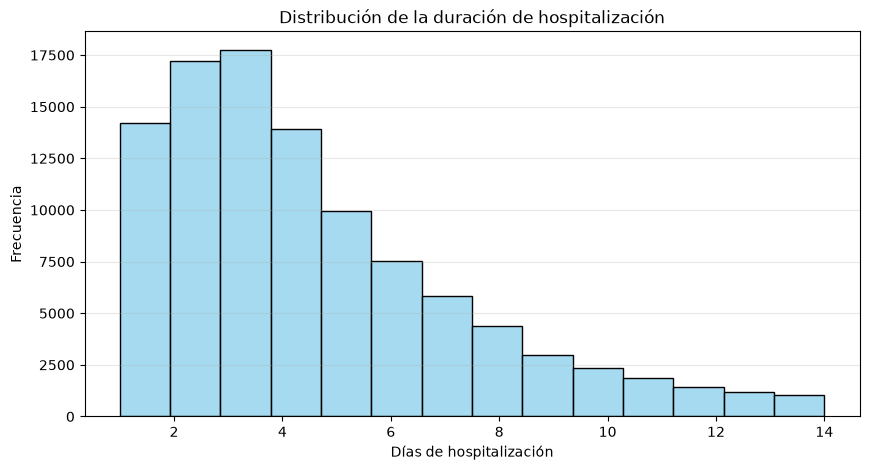

In [41]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="time_in_hospital",
    bins=14,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribución de la duración de hospitalización")
plt.xlabel("Días de hospitalización")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)

plt.show()

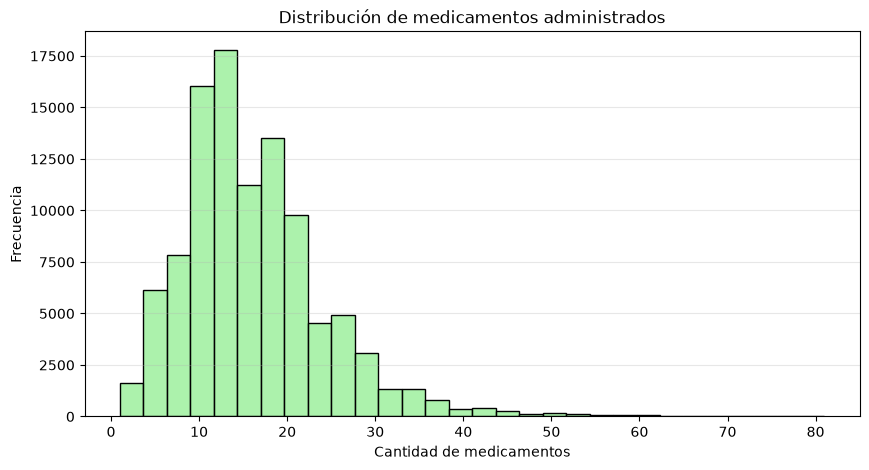

In [42]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="num_medications",
    bins=30,
    color="lightgreen",
    edgecolor="black"
)

plt.title("Distribución de medicamentos administrados")
plt.xlabel("Cantidad de medicamentos")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)

plt.show()


## Interpretación de los histogramas

**Duración de hospitalización:** La duración promedio es de 4,40 días, con una mediana de 4 días. Los registros presentan una duración mínima de 1 día y máxima de 14 días.

**Medicamentos administrados:** La cantidad promedio es de 16,02 medicamentos distintos, con una mediana de 15. Los valores oscilan entre 1 y 81 medicamentos.

Las diferencias entre los valores mínimos y máximos muestran que ambas variables tienen escalas distintas. Esto será importante al aplicar las técnicas de normalización y estandarización.


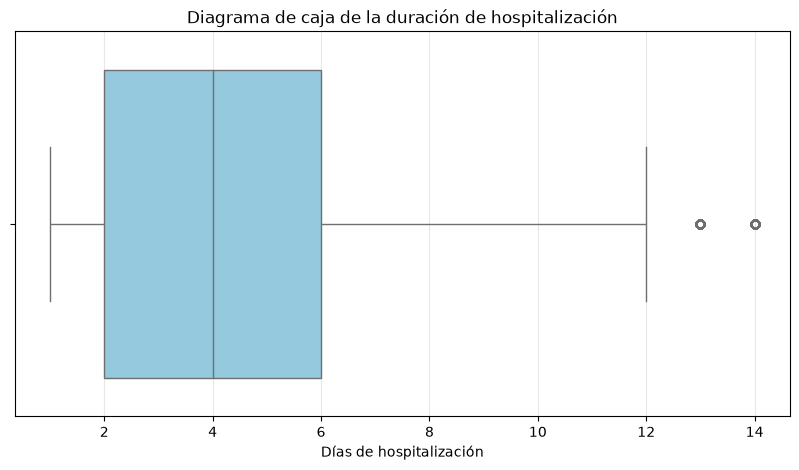

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["time_in_hospital"],
    color="skyblue"
)

plt.title("Diagrama de caja de la duración de hospitalización")
plt.xlabel("Días de hospitalización")
plt.grid(axis="x", alpha=0.3)

plt.show()

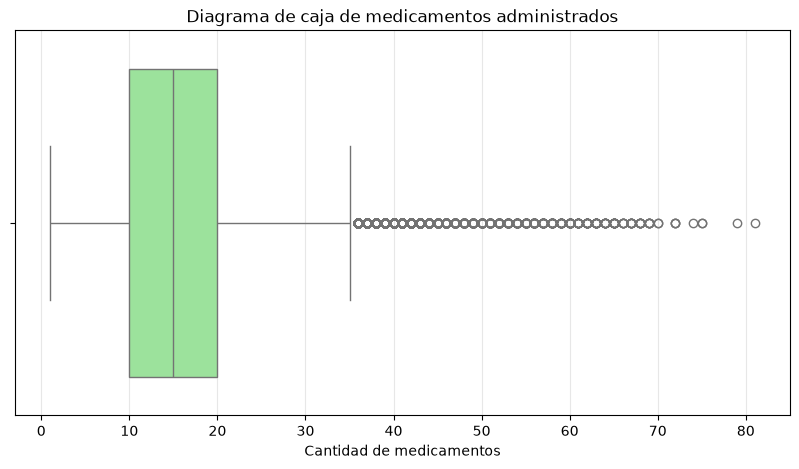

In [44]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["num_medications"],
    color="lightgreen"
)

plt.title("Diagrama de caja de medicamentos administrados")
plt.xlabel("Cantidad de medicamentos")
plt.grid(axis="x", alpha=0.3)

plt.show()


## Interpretación de los diagramas de caja

**Duración de hospitalización:** La mediana es de 4 días, mientras que el primer cuartil corresponde a 2 días y el tercer cuartil a 6 días. Esto indica que el 50 % central de las hospitalizaciones dura entre 2 y 6 días.

**Medicamentos administrados:** La mediana es de 15 medicamentos, con un primer cuartil de 10 y un tercer cuartil de 20. Esto significa que el 50 % central de los registros presenta entre 10 y 20 medicamentos distintos.

Los diagramas de caja permiten identificar valores alejados de la distribución principal. Estos posibles valores atípicos deberán analizarse antes de decidir si corresponde conservarlos o tratarlos.



## Frecuencia de readmisiones hospitalarias

En esta sección se analiza la variable categórica `readmitted`, que indica si existe una readmisión hospitalaria después del alta.

Las categorías son:

- **NO:** no se registró una readmisión.
- **<30:** readmisión antes de 30 días.
- **>30:** readmisión después de 30 días.

El gráfico de barras permite comparar la frecuencia de cada categoría e identificar cuál es la más frecuente.


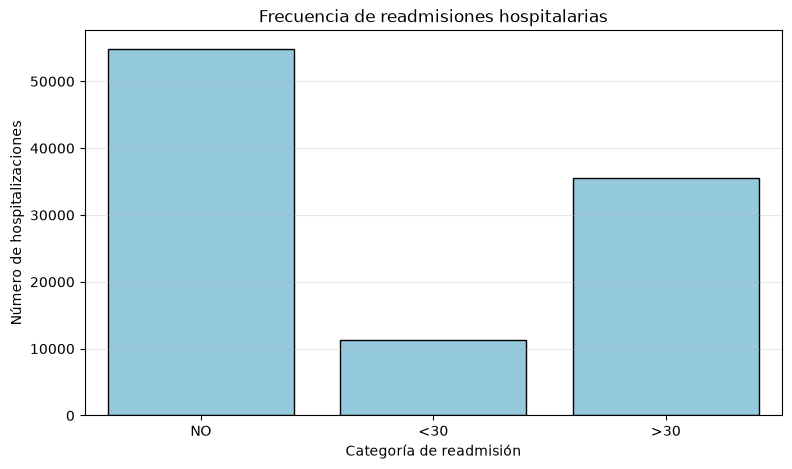

,Frecuencia,Porcentaje (%)
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

orden = ["NO", "<30", ">30"]

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="readmitted",
    order=orden,
    color="skyblue",
    edgecolor="black"
)

plt.title("Frecuencia de readmisiones hospitalarias")
plt.xlabel("Categoría de readmisión")
plt.ylabel("Número de hospitalizaciones")
plt.grid(axis="y", alpha=0.3)

plt.show()

frecuencias = df["readmitted"].value_counts()
porcentajes = df["readmitted"].value_counts(normalize=True) * 100

tabla_readmisiones = pd.DataFrame({
    "Frecuencia": frecuencias,
    "Porcentaje (%)": porcentajes.round(2)
})

display(tabla_readmisiones)


## Interpretación de las readmisiones hospitalarias

El análisis muestra que el 53,91 % de las hospitalizaciones no presentan una readmisión registrada, siendo esta la categoría más frecuente.

Por otro lado, el 34,93 % corresponde a readmisiones después de 30 días y el 11,16 % a readmisiones antes de 30 días.

Estos resultados permiten conocer la distribución de las readmisiones hospitalarias, aunque no permiten identificar sus causas.



## Detección de valores atípicos mediante IQR

El rango intercuartílico (IQR) permite identificar valores que se encuentran alejados de la distribución principal de los datos.

Se analizan las variables `time_in_hospital` y `num_medications`, calculando sus cuartiles, límites inferior y superior, cantidad y porcentaje de valores atípicos.

Los valores detectados no serán eliminados automáticamente, porque pueden representar hospitalizaciones reales con características particulares.


In [46]:
import pandas as pd

variables_iqr = ["time_in_hospital", "num_medications"]

resultados_iqr = []

for variable in variables_iqr:

    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    atipicos = (
        (df[variable] < limite_inferior) |
        (df[variable] > limite_superior)
    )

    cantidad = atipicos.sum()
    porcentaje = cantidad / len(df) * 100

    resultados_iqr.append({
        "Variable": variable,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Valores atípicos": cantidad,
        "Porcentaje (%)": round(porcentaje, 2)
    })

tabla_iqr = pd.DataFrame(resultados_iqr)

display(tabla_iqr)

,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Valores atípicos,Porcentaje (%)
0,time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252,2.21
1,num_medications,10.0,20.0,10.0,-5.0,35.0,2557,2.51



## Interpretación de los valores atípicos

El método IQR permite identificar posibles valores atípicos en la duración de hospitalización y la cantidad de medicamentos administrados.

Para `time_in_hospital`, los valores superiores a 12 días se consideran posibles valores atípicos.

Para `num_medications`, los valores superiores a 35 medicamentos se consideran posibles valores atípicos.

Se decide conservar estos registros porque pueden representar situaciones hospitalarias reales. Eliminarlos únicamente por superar los límites estadísticos podría provocar pérdida de información importante.

Los valores atípicos pueden influir en los resultados de la normalización Min-Max y de la estandarización Z-score.



# Fase 3: Preparación de los datos (CRISP-DM)

## Selección y limpieza de variables

En esta fase se preparan las variables cuantitativas para aplicar las técnicas de normalización y estandarización.

Se seleccionan siete variables relacionadas con la duración de hospitalización, procedimientos médicos, medicamentos y visitas hospitalarias.

Los identificadores de pacientes y los códigos categóricos no serán escalados, debido a que no representan mediciones cuantitativas.

Se conservarán los valores atípicos identificados, ya que pueden representar situaciones hospitalarias reales. También se verificará que las variables seleccionadas no contengan valores faltantes.

La limpieza se realizará sobre una copia del dataset original para conservar la información sin modificar.


In [47]:
import pandas as pd

variables_seleccionadas = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

df_limpio = df.copy()

datos_numericos = df_limpio[variables_seleccionadas].copy()

for columna in variables_seleccionadas:
    datos_numericos[columna] = pd.to_numeric(
        datos_numericos[columna],
        errors="coerce"
    )

print("Dimensiones originales:", df.shape)
print("Dimensiones de la copia completa:", df_limpio.shape)
print("Dimensiones de las variables seleccionadas:", datos_numericos.shape)

print("\nValores faltantes por variable:")
display(datos_numericos.isna().sum().to_frame("Valores faltantes"))

print("\nTipos de datos:")
display(datos_numericos.dtypes.to_frame("Tipo de dato"))

print("\nPrimeros 10 registros:")
display(datos_numericos.head(10))

print("\nTotal de registros conservados:", len(datos_numericos))

assert len(datos_numericos) == len(df)
assert datos_numericos.isna().sum().sum() == 0

Dimensiones originales: (101766, 50)
Dimensiones de la copia completa: (101766, 50)
Dimensiones de las variables seleccionadas: (101766, 7)

Valores faltantes por variable:


,Valores faltantes
time_in_hospital,0
num_lab_procedures,0
num_procedures,0
num_medications,0
number_outpatient,0
number_emergency,0
number_inpatient,0



Tipos de datos:


,Tipo de dato
time_in_hospital,int64
num_lab_procedures,int64
num_procedures,int64
num_medications,int64
number_outpatient,int64
number_emergency,int64
number_inpatient,int64



Primeros 10 registros:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0
5,3,31,6,16,0,0,0
6,4,70,1,21,0,0,0
7,5,73,0,12,0,0,0
8,13,68,2,28,0,0,0
9,12,33,3,18,0,0,0



Total de registros conservados: 101766



## Registro de limpieza de datos

Durante la preparación se seleccionaron siete variables cuantitativas.

Se mantuvieron los registros originales y no se eliminaron hospitalizaciones repetidas de un mismo paciente, debido a que pueden corresponder a encuentros hospitalarios diferentes.

Los valores atípicos también fueron conservados para evitar la pérdida de información.

Se excluyeron del escalamiento los identificadores `encounter_id` y `patient_nbr`, los códigos categóricos y la variable de referencia `readmitted`.

Se verificaron los tipos de datos y la ausencia de valores faltantes en las variables seleccionadas.

Esta preparación permite aplicar posteriormente las técnicas de normalización Min-Max y estandarización Z-score sobre los mismos registros.



## Normalización de datos mediante Min-Max

La normalización Min-Max es una técnica de preprocesamiento que permite transformar los valores numéricos a una escala entre 0 y 1.

En esta práctica se utiliza `MinMaxScaler` de la biblioteca scikit-learn para normalizar las siete variables cuantitativas seleccionadas.

Esta transformación facilita la comparación de variables que originalmente presentan diferentes rangos de valores.

Los datos normalizados se almacenarán en una nueva tabla para conservar los valores originales.


In [48]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np

normalizador = MinMaxScaler(feature_range=(0, 1))

datos_normalizados = pd.DataFrame(
    normalizador.fit_transform(datos_numericos.copy()),
    columns=datos_numericos.columns,
    index=datos_numericos.index
)

print("Dimensiones:", datos_normalizados.shape)

print("\nPrimeros 10 registros normalizados:")
display(datos_normalizados.head(10))

Dimensiones: (101766, 7)

Primeros 10 registros normalizados:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000
9,0.846154,0.244275,0.500000,0.2125,0.000000,0.0,0.000000


In [49]:

comparacion_minmax = pd.DataFrame({
    "Mínimo original": datos_numericos.min(),
    "Máximo original": datos_numericos.max(),
    "Mínimo normalizado": datos_normalizados.min(),
    "Máximo normalizado": datos_normalizados.max()
})

display(comparacion_minmax.round(4))

constantes = datos_numericos.nunique() == 1

minimos_correctos = np.allclose(
    datos_normalizados.min().to_numpy(), 0, atol=1e-10
)

maximos_esperados = np.where(constantes.to_numpy(), 0, 1)

maximos_correctos = np.allclose(
    datos_normalizados.max().to_numpy(),
    maximos_esperados,
    atol=1e-10
)

print("Mínimos correctos:", minimos_correctos)
print("Máximos correctos:", maximos_correctos)
print("Filas conservadas:", len(datos_normalizados))
print("Índice conservado:", datos_normalizados.index.equals(datos_numericos.index))

assert minimos_correctos and maximos_correctos
assert datos_normalizados.index.equals(datos_numericos.index)


,Mínimo original,Máximo original,Mínimo normalizado,Máximo normalizado
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


Mínimos correctos: True
Máximos correctos: True
Filas conservadas: 101766
Índice conservado: True



## Interpretación de la normalización Min-Max

La normalización Min-Max permite transformar los valores originales de las siete variables cuantitativas a un intervalo entre 0 y 1.

Los valores mínimos se convierten en 0 y los máximos en 1, mientras que los demás valores se distribuyen proporcionalmente dentro del intervalo.

Los valores extremos pueden afectar la normalización porque determinan los límites de la escala y pueden comprimir la mayoría de los datos en un rango pequeño.

Cuando una variable es constante, MinMaxScaler transforma todos sus valores a 0 con el rango utilizado en esta práctica, evitando la división entre cero.

Este procedimiento conserva las 101.766 hospitalizaciones y facilita la comparación de variables que originalmente tenían escalas diferentes.



## Estandarización de datos mediante Z-score

La estandarización Z-score es una técnica de preprocesamiento que transforma las variables cuantitativas para obtener una media aproximadamente igual a 0 y una desviación estándar aproximadamente igual a 1.

En esta práctica se utiliza `StandardScaler` de la biblioteca scikit-learn para estandarizar las siete variables seleccionadas.

A diferencia de Min-Max, los datos estandarizados pueden presentar valores negativos y superiores a 1.

La estandarización se realizará sobre una copia de los datos numéricos originales limpios, sin utilizar los valores previamente normalizados.


In [50]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

estandarizador = StandardScaler()

datos_estandarizados = pd.DataFrame(
    estandarizador.fit_transform(datos_numericos.copy()),
    columns=datos_numericos.columns,
    index=datos_numericos.index
)

print("Dimensiones:", datos_estandarizados.shape)

print("\nPrimeros 10 registros estandarizados:")
display(datos_estandarizados.head(10))

Dimensiones: (101766, 7)

Primeros 10 registros estandarizados:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276
9,2.547329,-0.513139,0.973309,0.243390,-0.291461,-0.21262,-0.503276


In [51]:
comparacion_zscore = pd.DataFrame({
    "Media original": datos_numericos.mean(),
    "Desviación original": datos_numericos.std(ddof=0),
    "Media estandarizada": datos_estandarizados.mean(),
    "Desviación estandarizada": datos_estandarizados.std(ddof=0)
})

display(comparacion_zscore.round(6))

constantes_z = datos_numericos.nunique() == 1

medias_correctas = np.allclose(
    datos_estandarizados.mean().to_numpy(),
    0,
    atol=1e-10
)

desviaciones_esperadas = np.where(
    constantes_z.to_numpy(), 0, 1
)

desviaciones_correctas = np.allclose(
    datos_estandarizados.std(ddof=0).to_numpy(),
    desviaciones_esperadas,
    atol=1e-10
)

print("Medias correctas:", medias_correctas)
print("Desviaciones correctas:", desviaciones_correctas)
print("Filas conservadas:", len(datos_estandarizados))
print("Índice conservado:", datos_estandarizados.index.equals(datos_numericos.index))

assert medias_correctas and desviaciones_correctas
assert datos_estandarizados.index.equals(datos_numericos.index)

,Media original,Desviación original,Media estandarizada,Desviación estandarizada
time_in_hospital,4.395987,2.985093,0.0,1.0
num_lab_procedures,43.095641,19.674266,0.0,1.0
num_procedures,1.339730,1.705799,-0.0,1.0
num_medications,16.021844,8.127526,-0.0,1.0
number_outpatient,0.369357,1.267259,0.0,1.0
number_emergency,0.197836,0.930468,0.0,1.0
number_inpatient,0.635566,1.262857,-0.0,1.0


Medias correctas: True
Desviaciones correctas: True
Filas conservadas: 101766
Índice conservado: True



## Interpretación de la estandarización Z-score

La estandarización Z-score permite transformar las siete variables cuantitativas para que tengan una media aproximadamente igual a 0 y una desviación estándar aproximadamente igual a 1.

Los valores negativos indican observaciones inferiores a la media, mientras que los valores positivos representan observaciones superiores a la media.

A diferencia de la normalización Min-Max, los valores estandarizados no están limitados al intervalo entre 0 y 1.

Esta transformación permite comparar variables con diferentes unidades y escalas. Sin embargo, los valores extremos pueden influir en la media y la desviación estándar.

Cuando una variable es constante, StandardScaler transforma sus valores a 0 y su desviación estándar resultante también es 0.

Se conservaron los 101.766 registros originales y las siete variables seleccionadas.



## Comparación de datos originales, normalizados y estandarizados

En esta sección se comparan las estadísticas de las siete variables cuantitativas antes y después de aplicar las técnicas de escalamiento.

Se analizan los valores mínimos, máximos, medias y desviaciones estándar de los datos originales, normalizados mediante Min-Max y estandarizados mediante Z-score.

Esta comparación permite identificar las diferencias entre ambas transformaciones y comprender cómo afectan las escalas de los datos.


In [52]:
import pandas as pd

def calcular_estadisticas(datos, version):

    tabla = pd.DataFrame({
        "Mínimo": datos.min(),
        "Máximo": datos.max(),
        "Media": datos.mean(),
        "Desviación estándar": datos.std(ddof=0)
    })

    tabla = tabla.rename_axis("Variable").reset_index()
    tabla.insert(0, "Versión", version)

    return tabla

tabla_original = calcular_estadisticas(
    datos_numericos, "Original"
)

tabla_normalizada = calcular_estadisticas(
    datos_normalizados, "Normalizado"
)

tabla_estandarizada = calcular_estadisticas(
    datos_estandarizados, "Estandarizado"
)

tabla_comparacion = pd.concat(
    [
        tabla_original,
        tabla_normalizada,
        tabla_estandarizada
    ],
    ignore_index=True
)

display(tabla_comparacion.round(4))

,Versión,Variable,Mínimo,Máximo,Media,Desviación estándar
0,Original,time_in_hospital,1.0000,14.0000,4.3960,2.9851
1,Original,num_lab_procedures,1.0000,132.0000,43.0956,19.6743
2,Original,num_procedures,0.0000,6.0000,1.3397,1.7058
3,Original,num_medications,1.0000,81.0000,16.0218,8.1275
4,Original,number_outpatient,0.0000,42.0000,0.3694,1.2673
5,Original,number_emergency,0.0000,76.0000,0.1978,0.9305
6,Original,number_inpatient,0.0000,21.0000,0.6356,1.2629
7,Normalizado,time_in_hospital,0.0000,1.0000,0.2612,0.2296
8,Normalizado,num_lab_procedures,0.0000,1.0000,0.3213,0.1502
9,Normalizado,num_procedures,0.0000,1.0000,0.2233,0.2843



## Interpretación de la comparación estadística

Los datos originales presentan diferentes escalas debido a las características de cada variable cuantitativa.

Después de aplicar Min-Max, todas las variables tienen valores entre 0 y 1. Sin embargo, sus medias y desviaciones estándar no necesariamente son iguales.

Por otro lado, la estandarización Z-score transforma los datos para obtener una media aproximadamente igual a 0 y una desviación estándar igual a 1.

Ambas técnicas conservan las diferencias proporcionales y el orden de los valores dentro de cada variable, pero modifican sus escalas.

Min-Max es útil cuando se necesita trabajar con valores dentro de un intervalo definido, mientras que Z-score es útil para comparar observaciones según su distancia respecto a la media.

Ninguna de estas transformaciones elimina automáticamente los valores atípicos ni corrige una distribución asimétrica.



## Comparación gráfica de las transformaciones

En esta sección se comparan las distribuciones de las variables `time_in_hospital` y `num_medications` en sus versiones original, normalizada y estandarizada.

El objetivo es observar cómo cambian las escalas después de aplicar Min-Max y Z-score.

Estas transformaciones modifican los valores del eje horizontal, pero conservan la forma general de las distribuciones, ya que son transformaciones lineales.


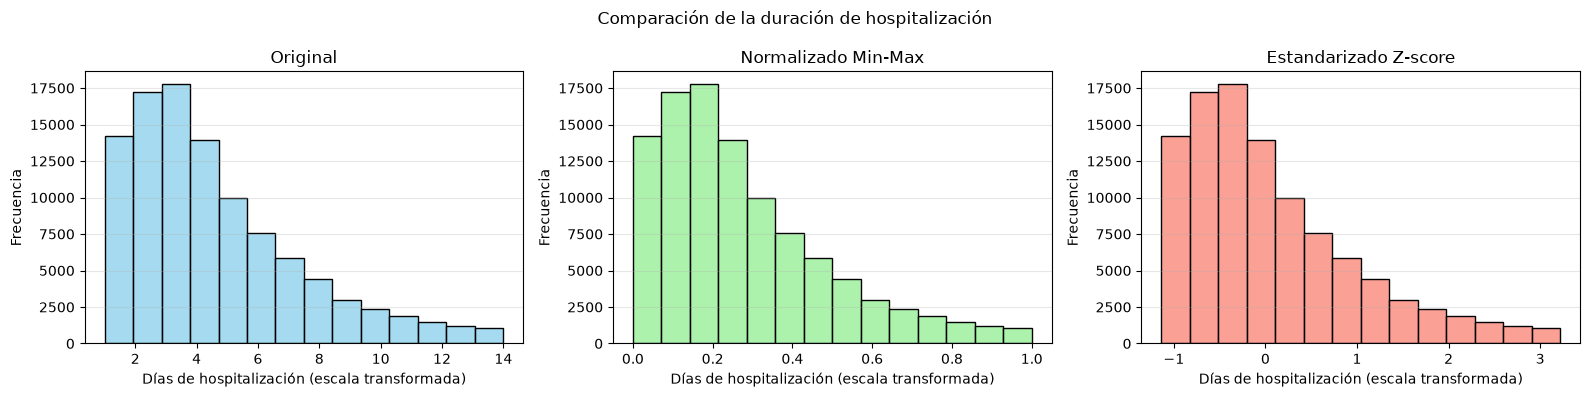

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

versiones = [
    (datos_numericos, "Original", "skyblue"),
    (datos_normalizados, "Normalizado Min-Max", "lightgreen"),
    (datos_estandarizados, "Estandarizado Z-score", "salmon")
]

for eje, (datos, titulo, color) in zip(ejes, versiones):
    sns.histplot(
        datos["time_in_hospital"],
        bins=14,
        color=color,
        edgecolor="black",
        ax=eje
    )

    eje.set_title(titulo)
    eje.set_xlabel("Días de hospitalización (escala transformada)")
    eje.set_ylabel("Frecuencia")
    eje.grid(axis="y", alpha=0.3)

plt.suptitle("Comparación de la duración de hospitalización")
plt.tight_layout()
plt.show()

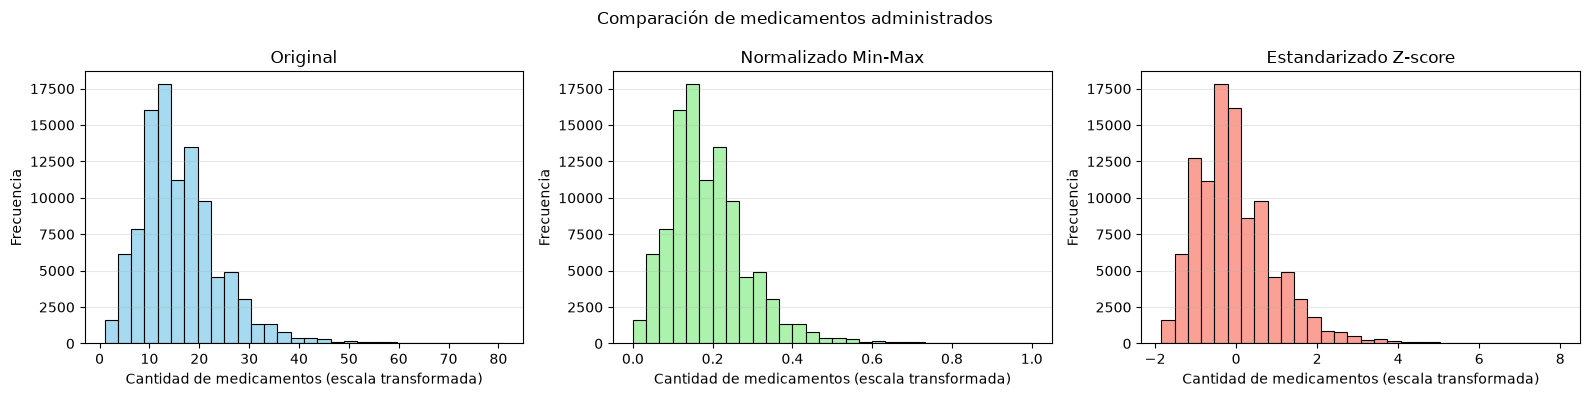

In [54]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

for eje, (datos, titulo, color) in zip(ejes, versiones):
    sns.histplot(
        datos["num_medications"],
        bins=30,
        color=color,
        edgecolor="black",
        ax=eje
    )

    eje.set_title(titulo)
    eje.set_xlabel("Cantidad de medicamentos (escala transformada)")
    eje.set_ylabel("Frecuencia")
    eje.grid(axis="y", alpha=0.3)

plt.suptitle("Comparación de medicamentos administrados")
plt.tight_layout()
plt.show()


## Interpretación de los gráficos comparativos

**Duración de hospitalización:** Los tres histogramas presentan la misma forma de distribución, pero muestran diferentes escalas en el eje horizontal. Min-Max transforma los valores al intervalo de 0 a 1, mientras que Z-score los expresa según su distancia respecto a la media.

**Medicamentos administrados:** La distribución conserva su asimetría hacia la derecha en las tres versiones. Esto demuestra que la normalización y la estandarización cambian la escala, pero no eliminan los valores extremos ni corrigen la asimetría.

En ambas variables se conserva el orden de los registros y la forma de las distribuciones, lo que permite comparar el efecto de cada técnica.



## Comprobación manual de Min-Max y Z-score

En esta sección se seleccionan cinco valores de la variable `time_in_hospital` para realizar los cálculos de normalización y estandarización mediante sus fórmulas matemáticas.

**Normalización Min-Max:**

\[
X_{norm} = \frac{X-X_{min}}{X_{max}-X_{min}}
\]

**Estandarización Z-score:**

\[
Z = \frac{X-\mu}{\sigma}
\]

Los resultados manuales se compararán con los obtenidos mediante `MinMaxScaler` y `StandardScaler` para verificar que ambas transformaciones se aplicaron correctamente.


In [55]:
variable = "time_in_hospital"

muestra = datos_numericos[variable].drop_duplicates().head(5)

minimo = datos_numericos[variable].min()
maximo = datos_numericos[variable].max()
media = datos_numericos[variable].mean()
desviacion = datos_numericos[variable].std(ddof=0)

minmax_manual = (muestra - minimo) / (maximo - minimo)
zscore_manual = (muestra - media) / desviacion

tabla_manual = pd.DataFrame({
    "Valor original": muestra,
    "Min-Max manual": minmax_manual,
    "Min-Max Python": datos_normalizados.loc[muestra.index, variable],
    "Z-score manual": zscore_manual,
    "Z-score Python": datos_estandarizados.loc[muestra.index, variable]
})

print("Mínimo:", minimo)
print("Máximo:", maximo)
print("Media:", round(media, 6))
print("Desviación estándar:", round(desviacion, 6))

print("\nComparación de los cinco valores:")
display(tabla_manual.round(6))

print("Min-Max coincide:", np.allclose(
    tabla_manual["Min-Max manual"],
    tabla_manual["Min-Max Python"]
))

print("Z-score coincide:", np.allclose(
    tabla_manual["Z-score manual"],
    tabla_manual["Z-score Python"]
))

Mínimo: 1
Máximo: 14
Media: 4.395987
Desviación estándar: 2.985093

Comparación de los cinco valores:


,Valor original,Min-Max manual,Min-Max Python,Z-score manual,Z-score Python
0,1,0.000000,0.000000,-1.137649,-1.137649
1,3,0.153846,0.153846,-0.467653,-0.467653
2,2,0.076923,0.076923,-0.802651,-0.802651
6,4,0.230769,0.230769,-0.132655,-0.132655
7,5,0.307692,0.307692,0.202343,0.202343


Min-Max coincide: True
Z-score coincide: True



## Desarrollo de los cálculos manuales

Para realizar la comprobación se utilizó la variable `time_in_hospital`, cuyos parámetros son:

- Mínimo: 1
- Máximo: 14
- Media: 4,395987
- Desviación estándar: 2,985093

### Ejemplo de normalización Min-Max

Para una hospitalización de 3 días:

$$
X_{norm} = \frac{3-1}{14-1} = 0.153846
$$

### Ejemplo de estandarización Z-score

Para el mismo valor de 3 días:

$$
Z = \frac{3-4.395987}{2.985093} \approx -0.467653
$$


## Interpretación de los cálculos

Los resultados obtenidos mediante las fórmulas manuales coinciden con los calculados por las herramientas de scikit-learn.

En Min-Max, los valores se transforman proporcionalmente al intervalo de 0 a 1.

En Z-score, los resultados indican cuántas desviaciones estándar se encuentra cada observación por encima o por debajo de la media.

La comparación de los cinco valores permite comprobar que las técnicas se aplicaron correctamente y que los datos mantienen su correspondencia con los registros originales.



## Exportación de datos normalizados y estandarizados

En esta sección se exportan los resultados de las transformaciones Min-Max y Z-score a archivos CSV.

Se generan dos archivos:

- `datos_normalizados.csv`
- `datos_estandarizados.csv`

Ambos contienen las siete variables cuantitativas transformadas y mantienen la correspondencia con los registros originales mediante su índice.

También se verificará que los archivos se hayan guardado correctamente y que no existan diferencias en la cantidad de registros.


In [56]:
import pandas as pd
import numpy as np
import os

datos_normalizados.to_csv(
    "datos_normalizados.csv",
    index=True,
    index_label="indice_original"
)

datos_estandarizados.to_csv(
    "datos_estandarizados.csv",
    index=True,
    index_label="indice_original"
)

normalizados_csv = pd.read_csv(
    "datos_normalizados.csv",
    index_col="indice_original"
)

estandarizados_csv = pd.read_csv(
    "datos_estandarizados.csv",
    index_col="indice_original"
)

print("Archivo normalizado:", normalizados_csv.shape)
print("Archivo estandarizado:", estandarizados_csv.shape)

print("\nÍndices iguales:",
      normalizados_csv.index.equals(estandarizados_csv.index))

print("Columnas iguales:",
      normalizados_csv.columns.equals(estandarizados_csv.columns))

print("Datos normalizados correctos:",
      np.allclose(normalizados_csv, datos_normalizados))

print("Datos estandarizados correctos:",
      np.allclose(estandarizados_csv, datos_estandarizados))

print("\nArchivos guardados en:")
print(os.getcwd())

print("\nExportación completada correctamente.")

Archivo normalizado: (101766, 7)
Archivo estandarizado: (101766, 7)

Índices iguales: True
Columnas iguales: True
Datos normalizados correctos: True
Datos estandarizados correctos: True

Archivos guardados en:
C:\Users\ACER\Desktop\Practicas Maching learning\Notebooks

Exportación completada correctamente.



## Interpretación de la exportación

Se generaron dos archivos CSV que contienen las siete variables cuantitativas transformadas mediante normalización Min-Max y estandarización Z-score.

Ambos archivos conservan los 101.766 registros y el mismo orden de las hospitalizaciones.

El índice de referencia permite relacionar las filas transformadas con sus registros originales.

Se verificó que las columnas, los índices y los valores exportados coincidan con los resultados obtenidos en Python.

Estos archivos podrán utilizarse posteriormente en otras actividades de análisis de datos y Machine Learning.



# Conclusiones generales

1. Mediante la metodología CRISP-DM se logró analizar un conjunto de datos médicos compuesto por 101.766 hospitalizaciones y 50 variables, correspondientes a 71.518 pacientes únicos. Esto permitió comprender la estructura y las características de la información antes de realizar las transformaciones.

2. El análisis exploratorio permitió identificar valores faltantes, registros de pacientes repetidos y posibles valores atípicos. Se encontró que el 53,91 % de las hospitalizaciones no presentó una readmisión registrada, mientras que el 34,93 % correspondió a readmisiones después de 30 días y el 11,16 % a readmisiones antes de 30 días.

3. Se identificaron 2.252 valores atípicos en la duración de hospitalización y 2.557 en la cantidad de medicamentos administrados. Se decidió conservarlos porque pueden representar situaciones hospitalarias reales y su eliminación podría provocar pérdida de información.

4. La normalización Min-Max permitió transformar correctamente las siete variables cuantitativas al intervalo entre 0 y 1. Esta técnica resulta útil cuando se necesita trabajar con variables dentro de una escala definida.

5. La estandarización Z-score permitió obtener variables con una media aproximadamente igual a 0 y una desviación estándar igual a 1. Esta transformación permite comparar los valores según su distancia respecto a la media.

6. Al comparar ambas técnicas, se comprobó que modifican las escalas, pero conservan la forma general de las distribuciones. Además, los cálculos manuales coincidieron con los resultados obtenidos mediante Python.

7. Finalmente, se exportaron correctamente los archivos CSV, conservando los 101.766 registros y su correspondencia con los datos originales. El análisis se limitó a las fases de comprensión y preparación de datos, sin entrenar modelos ni establecer relaciones causales.



# Preguntas de reflexión

### 1. ¿Por qué un código categórico numérico no debe escalarse como una medición?

Porque los números utilizados como códigos categóricos representan categorías y no cantidades reales. Por ejemplo, `admission_type_id` identifica tipos de admisión hospitalaria. Normalizar estos códigos podría generar una interpretación incorrecta de las distancias entre categorías.

### 2. ¿Cómo afectaría un valor extremo a Min-Max y a Z-score?

En Min-Max, un valor extremo puede ampliar el rango y provocar que la mayoría de los datos se concentre cerca de 0. En Z-score, los valores extremos pueden modificar la media y la desviación estándar, afectando los resultados de la transformación.

### 3. ¿Por qué una readmisión del mismo paciente no es necesariamente un duplicado?

Porque un mismo paciente puede ingresar varias veces al hospital en diferentes fechas. Cada hospitalización representa un encuentro diferente y contiene información válida. Por esta razón, no se deben eliminar registros únicamente porque tengan el mismo identificador de paciente.

### 4. ¿Qué diferencia hay entre cambiar de escala y corregir una distribución asimétrica?

Cambiar de escala consiste en modificar los valores numéricos manteniendo su orden y distribución general. En cambio, corregir una distribución asimétrica implica aplicar técnicas que modifiquen su forma. Min-Max y Z-score cambian la escala, pero no eliminan la asimetría de los datos.

### 5. ¿Cómo evitaría la fuga de información si posteriormente entrenara un modelo?

Primero dividiría los datos en conjuntos de entrenamiento y prueba, evitando que las hospitalizaciones del mismo paciente aparezcan en ambos conjuntos. Después ajustaría los escaladores únicamente con los datos de entrenamiento y utilizaría esos mismos parámetros para transformar los datos de prueba. Así evitaría utilizar información del conjunto de prueba durante la preparación del modelo.



# Referencias bibliográficas

Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J

Scikit-learn developers. (s. f.). *MinMaxScaler*. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html

Scikit-learn developers. (s. f.). *StandardScaler*. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

## Asistencia de inteligencia artificial

Durante el desarrollo de la práctica se utilizó ChatGPT de OpenAI como herramienta de apoyo para organizar las fases de CRISP-DM, elaborar código en Python, comprender las técnicas de normalización y estandarización y redactar las interpretaciones.

Los resultados fueron obtenidos mediante la ejecución del código en JupyterLab utilizando el conjunto de datos de UCI.
